# Notebook 05 V9 — Imbalance-Aware Feature-Tokenized CNN–SE–Attention

**CIC-IDS2017 | 60 features | 15 classes | Kaggle T4 GPU | V9 experimental pilot**

Thí nghiệm kiểm chứng 6 chiến lược xử lý mất cân bằng (B0–B5) trên **một kiến trúc T4 cố định**: Feature Tokenizer → Multi-Scale CNN → SE → Multi-Head Self-Attention → 15-class classifier.

- Cùng dữ liệu `03B`, nguyên split train/val/test và feature order.
- `SimpleImputer` và `StandardScaler` **chỉ fit trên train**; oversampling chỉ áp dụng train.
- **Không kết hợp SMOTE/ADASYN với class weighting** trong so sánh chính để tránh bù mất cân bằng hai lần.
- SMOTE/ADASYN chỉ nhắm **XSS** (mặc định 388 → tối đa 900 mẫu); không tự tạo hàng ngàn Heartbleed/SQL Injection.
- Chọn model, checkpoint và benign bias bằng **validation 15-class Macro-F1**; chỉ đánh giá test sau khi khóa cấu hình.
- Kết quả là **exploratory pilot**, không là xác nhận độc lập: test 03B đã được xem từ các notebook trước.

**Giới hạn khoa học:** SMOTE/ADASYN trên flow features đã chuẩn hóa có thể tạo các giá trị packet/flag/port không hợp lệ. Đây là so sánh phương pháp, không coi dòng tổng hợp là packet/flow thực để dùng triển khai. Các lớp SQL Injection/Heartbleed quá hiếm để suy ra kết luận vững chắc.

## 1. Cấu hình chạy và đường dẫn Kaggle

In [28]:
from pathlib import Path
import json, time, random, hashlib, gc, shutil
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
import joblib
from IPython.display import display
import matplotlib.pyplot as plt

SEARCH_MODE = 'balanced'  # 'smoke', 'balanced', 'full'
INPUT_DIR = None          # explicit folder containing 03B artifacts if auto-discovery is ambiguous
OUTPUT = Path('/kaggle/working/nids_outputs/05_CNN_Ablation_V9_Imbalance') if Path('/kaggle/working').exists() else Path('reports/05_CNN_Ablation_V9_Imbalance')
OUTPUT.mkdir(parents=True, exist_ok=True)
SEED=42
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BUDGET={
 'smoke':   dict(epochs=2, patience=2, seeds=[42], batch=256),
 'balanced':dict(epochs=55,patience=10, seeds=[42,43,44],batch=256),
 'full':    dict(epochs=80,patience=13, seeds=[42,43,44,45,46],batch=256),
}[SEARCH_MODE]
def seed_everything(seed):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
print('DEVICE', DEVICE, 'GPU',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU', 'BUDGET', BUDGET)
# XSS-only oversampling: fixed before examining validation/test.
XSS_SYNTH_TARGET = 900
SMOTE_K_NEIGHBORS = 5
FOCAL_GAMMA = 1.5


DEVICE cuda GPU Tesla T4 BUDGET {'epochs': 55, 'patience': 10, 'seeds': [42, 43, 44], 'batch': 256}


## 2. Đọc artifact 03B và xác nhận các nhóm trùng đặc trưng không bị chéo split

In [29]:
needed=['cic_expanded_splits.parquet','feature_sets.json','experiment_manifest.json']
if INPUT_DIR is not None:
 candidates=[Path(INPUT_DIR)]
else:
 candidates=[]
 local=Path('/kaggle/working/nids_outputs/03B_CIC_Feature_Engineering')
 if local.is_dir():candidates.append(local)
 if Path('/kaggle/input').exists():
  candidates += [f.parent for f in Path('/kaggle/input').rglob(needed[0])]
valid=sorted({str(p.resolve()) for p in candidates if all((p/f).is_file() for f in needed)})
if len(valid)!=1:
 raise FileNotFoundError(f'Expected ONE complete Notebook 03B output; found {valid}. Add Input output 03B or set INPUT_DIR.')
input_dir=Path(valid[0]);split_path=input_dir/needed[0]
manifest=json.loads((input_dir/'experiment_manifest.json').read_text(encoding='utf8'))
feature_sets=json.loads((input_dir/'feature_sets.json').read_text(encoding='utf8'))
feature_variant=manifest['validation_selected_feature_set']
features=list(feature_sets[feature_variant]);N_FEATURES=len(features)
df=pd.read_parquet(split_path)
required={'Label','_binary_label','_split','_source_file','_source_row','_duplicate_group'}
assert required.issubset(df.columns),f'Missing columns: {required-set(df.columns)}'
assert len(df)==int(manifest['sample_rows'])
assert set(df['_split'].astype(str))=={'train','val','test'}
assert len(features)==len(set(features)) and set(features).issubset(df.columns)
assert all(not f.startswith('_') and f!='Label' for f in features)
assert df.groupby('_duplicate_group')['_split'].nunique().max()==1,'Exact duplicate group leaked across splits'
assert not df.duplicated(['_source_file','_source_row']).any(),'Duplicate source row'
labels=df['Label'].astype(str)
assert np.array_equal(df['_binary_label'].astype(int).to_numpy(),labels.ne('BENIGN').astype(int).to_numpy())
mask={p:df['_split'].eq(p).to_numpy() for p in ['train','val','test']}
enc=LabelEncoder().fit(labels.loc[mask['train']])
assert set(enc.classes_)==set(labels),'A class is absent from train'
y={p:enc.transform(labels.loc[m]).astype(np.int64) for p,m in mask.items()}
classes=enc.classes_.tolist();K=len(classes);benign_idx=int(enc.transform(['BENIGN'])[0]);all_ids=np.arange(K)
raw=df[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan).astype('float32')
sha=hashlib.sha256(split_path.read_bytes()).hexdigest()
print('INPUT:',split_path,'SHA256:',sha)
print('FEATURE SET:',feature_variant,'N_FEATURES:',N_FEATURES,'CLASSES:',K)
print('SPLIT:',{p:int(m.sum()) for p,m in mask.items()})
print(pd.crosstab(labels,df['_split']).to_string())
assert N_FEATURES==60 and K==15, 'This experiment expects the same 60-feature/15-class protocol as 04 V2'
(OUTPUT/'feature_names.json').write_text(json.dumps(features,ensure_ascii=False,indent=2),encoding='utf8')

INPUT: /kaggle/input/datasets/chienvoo/nids-outputs/nids_outputs_backup/nids_outputs/03B_CIC_Feature_Engineering/cic_expanded_splits.parquet SHA256: d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152
FEATURE SET: with_port N_FEATURES: 60 CLASSES: 15
SPLIT: {'train': 23922, 'val': 7862, 'test': 7409}
_split                        test  train   val
Label                                          
BENIGN                        1353   4279  1368
Bot                            387   1190   389
DDoS                           681   2107   712
DoS GoldenEye                  681   2096   723
DoS Hulk                       585   2136   779
DoS Slowhttptest               627   2186   687
DoS slowloris                  699   2077   724
FTP-Patator                    558   2259   683
Heartbleed                       2      8     1
Infiltration                     8     21     7
PortScan                       717   2102   681
SSH-Patator                    681   2112   707
Web Attack ï¿

1283

## 3. Preprocessing fit trên train; cùng phép biến đổi cho val/test

In [30]:
imputer=SimpleImputer(strategy='median',keep_empty_features=True)
scaler=StandardScaler()
train_imp=imputer.fit_transform(raw.loc[mask['train']])
X={'train':scaler.fit_transform(train_imp).astype(np.float32)}
for p in ['val','test']:
 X[p]=scaler.transform(imputer.transform(raw.loc[mask[p]])).astype(np.float32)
for p in X:
 assert X[p].shape==(len(y[p]),N_FEATURES) and np.isfinite(X[p]).all()
train_counts=np.bincount(y['train'],minlength=K)
print('Train count min / max:',train_counts.min(),train_counts.max())
print('No preprocessing fit on val/test.')
joblib.dump({'imputer':imputer,'scaler':scaler,'label_encoder':enc,'features':features,
 'feature_variant':feature_variant,'split_sha256':sha},OUTPUT/'preprocessing.joblib')

Train count min / max: 8 4279
No preprocessing fit on val/test.


['/kaggle/working/nids_outputs/05_CNN_Ablation_V9_Imbalance/preprocessing.joblib']

## 4. Kiến trúc T4: Feature Tokenization + Multi-Scale CNN + SE + MHSA

In [31]:
class FeatureTokenizer(nn.Module):
 def __init__(self,n_features,d_model):
  super().__init__()
  self.weight=nn.Parameter(torch.empty(n_features,d_model))
  self.bias=nn.Parameter(torch.empty(n_features,d_model))
  nn.init.normal_(self.weight,mean=0.,std=.02)
  nn.init.normal_(self.bias,mean=0.,std=.02)
 def forward(self,x):
  return x.unsqueeze(-1)*self.weight.unsqueeze(0)+self.bias.unsqueeze(0)

class SEChannels(nn.Module):
 def __init__(self,d_model,reduction=8):
  super().__init__()
  hidden=max(8,d_model//reduction)
  self.net=nn.Sequential(nn.Linear(d_model,hidden),nn.GELU(),nn.Linear(hidden,d_model),nn.Sigmoid())
 def forward(self,z):
  # z: B,F,D ; squeeze over feature-token positions
  return z * self.net(z.mean(dim=1)).unsqueeze(1)

class TokenResBlock(nn.Module):
 def __init__(self,d_model,dropout):
  super().__init__()
  self.norm=nn.LayerNorm(d_model)
  self.net=nn.Sequential(nn.Linear(d_model,2*d_model),nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d_model,d_model))
  self.dropout=nn.Dropout(dropout)
 def forward(self,x):return x+self.dropout(self.net(self.norm(x)))

class TokenizedCNNSEAttention(nn.Module):
 def __init__(self,n_features,n_classes,d_model=64,heads=4,dropout=.15,
              use_cnn=True,use_se=True,use_attn=True,use_raw=False):
  super().__init__()
  assert d_model%heads==0
  self.flags={'use_cnn':use_cnn,'use_se':use_se,'use_attn':use_attn,'use_raw':use_raw}
  self.tokenizer=FeatureTokenizer(n_features,d_model)
  self.norm0=nn.Identity()  # preserve scalar feature magnitude before feature mixing
  if use_cnn:
   self.convs=nn.ModuleList([nn.Conv1d(d_model,d_model,k,padding=k//2) for k in (1,3,5)])
   self.conv_fuse=nn.Sequential(nn.Conv1d(3*d_model,d_model,1),nn.GELU())
   self.norm_cnn=nn.LayerNorm(d_model)
  self.se=SEChannels(d_model) if use_se else nn.Identity()
  if use_attn:
   self.attn_norm=nn.LayerNorm(d_model)
   self.mha=nn.MultiheadAttention(d_model,heads,dropout=dropout,batch_first=True)
   self.attn_dropout=nn.Dropout(dropout)
  self.token_mlp=TokenResBlock(d_model,dropout)
  self.pool_gate=nn.Linear(d_model,1)
  rep_dim=3*d_model
  if use_raw:
   self.raw_mlp=nn.Sequential(nn.Linear(n_features,2*d_model),nn.LayerNorm(2*d_model),nn.GELU(),
                              nn.Dropout(dropout),nn.Linear(2*d_model,d_model),nn.GELU())
   rep_dim+=d_model
  self.classifier=nn.Sequential(nn.LayerNorm(rep_dim),nn.Linear(rep_dim,2*d_model),nn.GELU(),
                                nn.Dropout(dropout),nn.Linear(2*d_model,n_classes))
 def forward(self,x):
  z=self.norm0(self.tokenizer(x))
  if self.flags['use_cnn']:
   q=z.transpose(1,2)
   mixed=self.conv_fuse(torch.cat([conv(q) for conv in self.convs],dim=1)).transpose(1,2)
   z=self.norm_cnn(z+mixed)
  z=self.se(z)
  if self.flags['use_attn']:
   q=self.attn_norm(z)
   z=z+self.attn_dropout(self.mha(q,q,q,need_weights=False)[0])
  z=self.token_mlp(z)
  weights=torch.softmax(self.pool_gate(z).squeeze(-1),dim=1)
  attentive=(z*weights.unsqueeze(-1)).sum(dim=1)
  reps=[attentive,z.mean(dim=1),z.amax(dim=1)]
  if self.flags['use_raw']:reps.append(self.raw_mlp(x))
  return self.classifier(torch.cat(reps,dim=1))

ARCHS={
 'T0_TokenOnly': dict(use_cnn=False,use_se=False,use_attn=False,use_raw=False),
 'T1_TokenCNN': dict(use_cnn=True,use_se=False,use_attn=False,use_raw=False),
 'T2_TokenCNN_SE': dict(use_cnn=True,use_se=True,use_attn=False,use_raw=False),
 'T3_TokenCNN_MHSA': dict(use_cnn=True,use_se=False,use_attn=True,use_raw=False),
 'T4_TokenCNN_SE_MHSA': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=False),
 'T5_TokenCNN_SE_MHSA_Raw': dict(use_cnn=True,use_se=True,use_attn=True,use_raw=True),
}
def make_model(arch,d_model=64,dropout=.15,heads=4):
 return TokenizedCNNSEAttention(N_FEATURES,K,d_model=d_model,dropout=dropout,heads=heads,**ARCHS[arch])
for name in ARCHS:
 m=make_model(name).to(DEVICE)
 xx=torch.randn(3,N_FEATURES,device=DEVICE)
 assert m(xx).shape==(3,K)
 m(xx).sum().backward()
 assert all(p.grad is not None for p in m.parameters() if p.requires_grad)
 print(name,sum(p.numel() for p in m.parameters()),'params; forward/backward OK')
 del m
if DEVICE.type=='cuda':torch.cuda.empty_cache()

T0_TokenOnly 51472 params; forward/backward OK
T1_TokenCNN 101008 params; forward/backward OK
T2_TokenCNN_SE 102104 params; forward/backward OK
T3_TokenCNN_MHSA 117776 params; forward/backward OK
T4_TokenCNN_SE_MHSA 118872 params; forward/backward OK
T5_TokenCNN_SE_MHSA_Raw 143512 params; forward/backward OK


## 5. Xử lý mất cân bằng và kiểm tra dữ liệu tổng hợp

6 điều kiện trên cùng kiến trúc/cấu hình:

| ID | Train strategy | Loss |
|---|---|---|
| B0 | Không resample | CE thường |
| B1 | Không resample | Class-weighted CE (power=0.25) |
| B2 | Không resample | Focal Loss (gamma=1.5, không class weight) |
| B3 | WeightedRandomSampler (chỉ train, clip trọng số) | CE thường |
| B4 | SMOTE chỉ XSS (tối đa 900) | CE thường |
| B5 | ADASYN chỉ XSS (tối đa xấp xỉ 900) | CE thường |

Lựa chọn oversampling chỉ XSS là chủ ý để kiểm tra nhầm lẫn XSS ↔ Web Brute Force. Trước khi áp dụng, kiểm tra lớp XSS hiện diện và ghi lại lượng mẫu được tạo. Tất cả dữ liệu biến đổi tạo ra vẫn phải có 60 chiều, không chứa NaN/Inf. `imbalanced-learn` được yêu cầu cho B4/B5; nếu thiếu, notebook sẽ báo cách cài và không âm thầm bỏ qua.

In [32]:
from torch.utils.data import WeightedRandomSampler
from dataclasses import dataclass, asdict

STRATEGIES = ['B0_CE','B1_WeightedCE','B2_Focal','B3_WeightedSampler','B4_SMOTE','B5_ADASYN']
T4_ARCH = 'T4_TokenCNN_SE_MHSA'
XSS_LABELS = [s for s in classes if 'XSS' in s.upper()]
assert len(XSS_LABELS)==1, f'Expected one XSS label, got {XSS_LABELS}'
XSS_ID=int(enc.transform(XSS_LABELS)[0])
WEB_BF_LABELS=[s for s in classes if 'Web Attack' in s and 'Brute Force' in s]
assert len(WEB_BF_LABELS)==1,WEB_BF_LABELS
WEB_BF_ID=int(enc.transform(WEB_BF_LABELS)[0])
assert len(np.unique(y['train']))==K
assert len(X['train'])==len(y['train'])
print('XSS',XSS_LABELS[0],'count',int(train_counts[XSS_ID]),'target',XSS_SYNTH_TARGET)
print('Web BF',WEB_BF_LABELS[0],'count',int(train_counts[WEB_BF_ID]))
assert XSS_SYNTH_TARGET>int(train_counts[XSS_ID]) and XSS_SYNTH_TARGET<=2000

try:
 from imblearn.over_sampling import SMOTE, ADASYN
except ImportError as exc:
 raise ImportError('Kaggle requires imbalanced-learn; add a setup cell: %pip install imbalanced-learn, restart session, Run All.') from exc

# Only train is resampled, on vectors that have already been fit-transformed from train.
synth_datasets={};resample_logs=[]
for strategy in ['B4_SMOTE','B5_ADASYN']:
 rs = (SMOTE(sampling_strategy={XSS_ID:XSS_SYNTH_TARGET},k_neighbors=SMOTE_K_NEIGHBORS,random_state=SEED)
       if strategy=='B4_SMOTE' else
       ADASYN(sampling_strategy={XSS_ID:XSS_SYNTH_TARGET},n_neighbors=SMOTE_K_NEIGHBORS,random_state=SEED))
 X_new,y_new=rs.fit_resample(X['train'],y['train'])
 X_new=np.asarray(X_new,dtype=np.float32);y_new=np.asarray(y_new,dtype=np.int64)
 assert X_new.shape[1]==N_FEATURES and np.isfinite(X_new).all()
 assert len(X_new)>len(X['train']) and len(y_new)==len(X_new)
 assert np.array_equal(y_new[:len(y['train'])],y['train'])
 assert np.array_equal(X_new[:len(X['train'])],X['train'])
 # Metadata/label leakage checks: original data untouched; only XSS synthetic rows appended.
 assert np.all(y_new[len(y['train']):]==XSS_ID)
 delta=len(X_new)-len(X['train'])
 synth_datasets[strategy]=(X_new,y_new)
 resample_logs.append({'strategy':strategy,'train_original':len(y['train']),
                        'train_after':len(y_new),'synthetic_count':delta,
                        'xss_before':int(train_counts[XSS_ID]),'xss_after':int(np.sum(y_new==XSS_ID)),
                        'finite':bool(np.isfinite(X_new).all())})
 print(strategy,'synthetic:',delta,'XSS after:',int(np.sum(y_new==XSS_ID)))

# Synthetic-flow plausibility diagnostic: discrete / count / flag features may become non-integers.
discrete_keywords=('Port','Packets','Flag','Win_bytes','Header Length','URG','PSH','ACK','SYN','FIN','RST','ECE','CWE','Count')
discrete_idx=[i for i,f in enumerate(features) if any(token.lower() in f.lower() for token in discrete_keywords)]
for entry in resample_logs:
 strategy=entry['strategy'];X_new,_=synth_datasets[strategy]
 if discrete_idx:
  generated=X_new[len(X['train']):,discrete_idx]
  # Convert back to original units using train-only scaler; this is a heuristic only.
  orig_units=generated*scaler.scale_[discrete_idx]+scaler.mean_[discrete_idx]
  entry['discrete_heuristic_noninteger_fraction']=float((np.abs(orig_units-np.rint(orig_units))>0.01).mean())
  print(strategy,'approx fraction of non-integer values in discrete-like features:',round(entry['discrete_heuristic_noninteger_fraction'],3))
pd.DataFrame(resample_logs).to_csv(OUTPUT/'resampling_quality_audit.csv',index=False)
print('Validation/test sizes unchanged:',len(y['val']),len(y['test']))

XSS Web Attack ï¿½ XSS count 388 target 900
Web BF Web Attack ï¿½ Brute Force count 945
B4_SMOTE synthetic: 512 XSS after: 900
B5_ADASYN synthetic: 477 XSS after: 865
B4_SMOTE approx fraction of non-integer values in discrete-like features: 0.144
B5_ADASYN approx fraction of non-integer values in discrete-like features: 0.14
Validation/test sizes unchanged: 7862 7409


## 6. Training loop: checkpoint chọn theo validation Macro-F1

In [33]:
@dataclass(frozen=True)
class Config:
 strategy:str
 seed:int=42
 d_model:int=64
 heads:int=4
 dropout:float=.15
 lr:float=.001
 weight_decay:float=.0001
 batch_size:int=256

# Class weighting intentionally only for B1. SMOTE/ADASYN are NOT stacked with class weights.
def class_weights(power=0.25):
 w=(train_counts.sum()/(K*np.maximum(train_counts,1)))**power
 w=np.clip(w,0.35,8.0);w=w/w.mean()
 return torch.tensor(w,dtype=torch.float32,device=DEVICE)

class FocalLoss(nn.Module):
 def __init__(self,gamma=1.5):
  super().__init__();self.gamma=gamma
 def forward(self,logits,targets):
  per=F.cross_entropy(logits,targets,reduction='none')
  pt=torch.exp(-per)
  return (((1-pt)**self.gamma)*per).mean()

def criterion_for(strategy):
 if strategy=='B1_WeightedCE':return nn.CrossEntropyLoss(weight=class_weights(.25))
 if strategy=='B2_Focal':return FocalLoss(gamma=FOCAL_GAMMA)
 return nn.CrossEntropyLoss()

def loader_for(part,strategy,batch,seed):
 if part=='train' and strategy in synth_datasets:
  xx,yy=synth_datasets[strategy]
 else:
  xx,yy=X[part],y[part]
 ds=TensorDataset(torch.from_numpy(xx),torch.from_numpy(yy))
 if part=='train' and strategy=='B3_WeightedSampler':
  # Effective inverse-count exponent .5 reduces overemphasis on 8-sample classes.
  weights=(np.maximum(train_counts,1)[yy].astype(np.float64))**(-0.5)
  sampler=WeightedRandomSampler(torch.from_numpy(weights),num_samples=len(yy),replacement=True,
                                generator=torch.Generator().manual_seed(seed))
  return DataLoader(ds,batch_size=batch,sampler=sampler,num_workers=0,pin_memory=(DEVICE.type=='cuda'))
 return DataLoader(ds,batch_size=batch,shuffle=(part=='train'),num_workers=0,
                   pin_memory=(DEVICE.type=='cuda'),generator=torch.Generator().manual_seed(seed))

@torch.inference_mode()
def logits_for(model,part,batch=1024):
 model.eval();out=[]
 for xb,_ in loader_for(part,'B0_CE',batch,SEED):
  out.append(model(xb.to(DEVICE,non_blocking=True)).float().cpu().numpy())
 return np.concatenate(out,axis=0)

def performance(truth,pred):
 is_attack=np.asarray(truth)!=benign_idx
 pred_attack=np.asarray(pred)!=benign_idx
 tn=int((~is_attack & ~pred_attack).sum());fp=int((~is_attack & pred_attack).sum())
 xss=(np.asarray(truth)==XSS_ID)
 return dict(accuracy=float(accuracy_score(truth,pred)),
             macro_f1=float(f1_score(truth,pred,labels=all_ids,average='macro',zero_division=0)),
             weighted_f1=float(f1_score(truth,pred,labels=all_ids,average='weighted',zero_division=0)),
             xss_recall=float(recall_score(xss,np.asarray(pred)==XSS_ID,zero_division=0)),
             xss_f1=float(f1_score(xss,np.asarray(pred)==XSS_ID,zero_division=0)),
             attack_recall=float(recall_score(is_attack,pred_attack,zero_division=0)),
             fpr=float(fp/(tn+fp)) if tn+fp else None)

def run_trial(cfg,trial_id):
 seed_everything(cfg.seed)
 net=make_model(T4_ARCH,cfg.d_model,cfg.dropout,cfg.heads).to(DEVICE)
 opt=torch.optim.AdamW(net.parameters(),lr=cfg.lr,weight_decay=cfg.weight_decay)
 scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',patience=4,factor=.5,min_lr=1e-5)
 loss_fn=criterion_for(cfg.strategy)
 path=OUTPUT/'trials'/f'{trial_id:03d}_{cfg.strategy}_seed{cfg.seed}'
 path.mkdir(parents=True,exist_ok=True)
 best=(-1.,-1.);best_epoch=0;stale=0;logs=[];t0=time.perf_counter()
 for epoch in range(1,BUDGET['epochs']+1):
  net.train();running=0.;total=0
  for xb,yb in loader_for('train',cfg.strategy,cfg.batch_size,cfg.seed+epoch):
   xb=xb.to(DEVICE,non_blocking=True);yb=yb.to(DEVICE,non_blocking=True)
   opt.zero_grad(set_to_none=True)
   loss=loss_fn(net(xb),yb)
   if not torch.isfinite(loss):raise FloatingPointError(f'Nonfinite loss {cfg.strategy}')
   loss.backward();nn.utils.clip_grad_norm_(net.parameters(),2.);opt.step()
   running+=float(loss.item())*len(yb);total+=len(yb)
  z=logits_for(net,'val');pred=z.argmax(axis=1)
  scores=performance(y['val'],pred)
  scheduler.step(scores['macro_f1'])
  logs.append({'epoch':epoch,'train_loss':running/max(total,1),'lr':opt.param_groups[0]['lr'],**scores})
  if (scores['macro_f1'],scores['accuracy'])>best:
   best=(scores['macro_f1'],scores['accuracy']);stale=0;best_epoch=epoch
   torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in net.state_dict().items()},
               'config':asdict(cfg),'arch':T4_ARCH,'best_epoch':epoch,
               'split_sha256':sha,'features':features,'classes':classes},path/'best.pt')
  else:stale+=1
  if epoch==1 or epoch%10==0 or stale>=BUDGET['patience']:
   print(cfg.strategy,'seed',cfg.seed,'epoch',epoch,'valF1',round(scores['macro_f1'],4),
         'valXSS',round(scores['xss_f1'],4),'bestF1',round(best[0],4),flush=True)
  if stale>=BUDGET['patience']:break
 torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in net.state_dict().items()},
             'config':asdict(cfg),'arch':T4_ARCH,'last_epoch':epoch,'split_sha256':sha},path/'last.pt')
 pd.DataFrame(logs).to_csv(path/'history.csv',index=False)
 record={'trial_id':trial_id,**asdict(cfg),'best_val_macro_f1':best[0],
         'best_val_accuracy':best[1],'best_epoch':best_epoch,'epochs_run':epoch,
         'seconds':round(time.perf_counter()-t0,1),'checkpoint':str(path/'best.pt')}
 (path/'trial_summary.json').write_text(json.dumps(record,indent=2))
 del net,opt,scheduler,loss_fn;gc.collect()
 if DEVICE.type=='cuda':torch.cuda.empty_cache()
 return record

results=[]
def run_and_save(cfg):
 r=run_trial(cfg,len(results)+1);results.append(r)
 pd.DataFrame(results).to_csv(OUTPUT/'all_validation_trials.csv',index=False)
 return r

## 7. Stage A — 6 chiến lược, cùng seed và hyperparameters

Vòng đối chứng này giữ nguyên `d_model=64`, `heads=4`, `dropout=.15`, `lr=.001`, `weight_decay=1e-4`, `batch=256`. Chỉ khác phương pháp imbalance. 6 trial tương ứng B0–B5.

In [34]:
for strategy in STRATEGIES:
 run_and_save(Config(strategy=strategy,seed=SEED))
base_trials=pd.DataFrame(results)
base_trials.to_csv(OUTPUT/'imbalance_ablation_single_seed.csv',index=False)
print(base_trials[['strategy','best_val_macro_f1','best_val_accuracy','best_epoch']].to_string(index=False))

B0_CE seed 42 epoch 1 valF1 0.6591 valXSS 0.0 bestF1 0.6591
B0_CE seed 42 epoch 10 valF1 0.825 valXSS 0.0303 bestF1 0.825
B0_CE seed 42 epoch 20 valF1 0.8187 valXSS 0.0301 bestF1 0.8283
B0_CE seed 42 epoch 30 valF1 0.8274 valXSS 0.0301 bestF1 0.8342
B0_CE seed 42 epoch 32 valF1 0.827 valXSS 0.0301 bestF1 0.8342
B1_WeightedCE seed 42 epoch 1 valF1 0.6592 valXSS 0.0 bestF1 0.6592
B1_WeightedCE seed 42 epoch 10 valF1 0.8207 valXSS 0.0303 bestF1 0.8324
B1_WeightedCE seed 42 epoch 20 valF1 0.834 valXSS 0.0301 bestF1 0.8354
B1_WeightedCE seed 42 epoch 30 valF1 0.838 valXSS 0.0299 bestF1 0.8452
B1_WeightedCE seed 42 epoch 40 valF1 0.8346 valXSS 0.0294 bestF1 0.8504
B1_WeightedCE seed 42 epoch 50 valF1 0.8385 valXSS 0.0299 bestF1 0.8574
B1_WeightedCE seed 42 epoch 54 valF1 0.835 valXSS 0.0299 bestF1 0.8574
B2_Focal seed 42 epoch 1 valF1 0.658 valXSS 0.0 bestF1 0.658
B2_Focal seed 42 epoch 10 valF1 0.8261 valXSS 0.0303 bestF1 0.8265
B2_Focal seed 42 epoch 20 valF1 0.8321 valXSS 0.0301 bestF1 0.

## 8. Stage B — kiểm tra độ ổn định của chiến lược đứng đầu

Chọn chiến lược bằng validation trên seed 42; chạy thêm seeds 43,44 (Balanced) hoặc 43–46 (Full). Giữ các hyperparameters ban đầu để không lẫn tác động của phương pháp imbalance với hyperparameter search. Các seed cùng dùng một split nên Mean ± Std là độ nhạy seed, **không** phản ánh tính độc lập của dữ liệu.

In [35]:
ranked=base_trials.sort_values(['best_val_macro_f1','best_val_accuracy'],ascending=False)
winning_strategy=str(ranked.iloc[0]['strategy'])
print('Validation winner, seed 42:',winning_strategy)
for sd in BUDGET['seeds'][1:]:
 run_and_save(Config(strategy=winning_strategy,seed=int(sd)))
trials=pd.DataFrame(results)
# Only matched hyperparams across seeds; we do not average unrelated configs.
seed_stats=trials.groupby('strategy',as_index=False).agg(
 val_macro_f1_mean=('best_val_macro_f1','mean'),
 val_macro_f1_std=('best_val_macro_f1','std'),
 n_seeds=('seed','nunique'))
seed_stats.to_csv(OUTPUT/'imbalance_seed_summary.csv',index=False)
display(seed_stats.sort_values('val_macro_f1_mean',ascending=False))

Validation winner, seed 42: B1_WeightedCE
B1_WeightedCE seed 43 epoch 1 valF1 0.6674 valXSS 0.0 bestF1 0.6674
B1_WeightedCE seed 43 epoch 10 valF1 0.8263 valXSS 0.0303 bestF1 0.8294
B1_WeightedCE seed 43 epoch 20 valF1 0.8327 valXSS 0.0303 bestF1 0.8327
B1_WeightedCE seed 43 epoch 30 valF1 0.8336 valXSS 0.0299 bestF1 0.8341
B1_WeightedCE seed 43 epoch 40 valF1 0.8302 valXSS 0.0294 bestF1 0.8385
B1_WeightedCE seed 43 epoch 50 valF1 0.843 valXSS 0.0301 bestF1 0.843
B1_WeightedCE seed 44 epoch 1 valF1 0.6764 valXSS 0.0 bestF1 0.6764
B1_WeightedCE seed 44 epoch 10 valF1 0.8315 valXSS 0.0303 bestF1 0.8315
B1_WeightedCE seed 44 epoch 20 valF1 0.8441 valXSS 0.0296 bestF1 0.8534
B1_WeightedCE seed 44 epoch 28 valF1 0.8481 valXSS 0.0299 bestF1 0.8534


,strategy,val_macro_f1_mean,val_macro_f1_std,n_seeds
4,B4_SMOTE,0.855530,NaN,1
1,B1_WeightedCE,0.851307,0.007365,3
2,B2_Focal,0.839323,NaN,1
0,B0_CE,0.834171,NaN,1
5,B5_ADASYN,0.833115,NaN,1
3,B3_WeightedSampler,0.830088,NaN,1


## 9. Stage C — lựa chọn final checkpoint và benign bias trên validation

Thử bias `[0, .25, .5, .75, 1.0]` cộng vào logit BENIGN để kiểm tra đánh đổi FPR/Macro-F1. Chọn duy nhất theo **Macro-F1 15 lớp**, tie-break Accuracy. Giữ riêng bảng Pareto FPR/XSS. Không đụng test tại giai đoạn này.

In [36]:
@torch.inference_mode()
def restore_logits(row,part):
 ck=torch.load(str(row['checkpoint']),map_location='cpu',weights_only=False)
 assert ck['split_sha256']==sha and ck['features']==features and ck['classes']==classes
 cfg=ck['config']
 net=make_model(T4_ARCH,int(cfg['d_model']),float(cfg['dropout']),int(cfg['heads'])).to(DEVICE)
 net.load_state_dict(ck['state_dict'],strict=True)
 logits=logits_for(net,part)
 del net,ck;gc.collect()
 if DEVICE.type=='cuda':torch.cuda.empty_cache()
 return logits

def pred_with_bias(z,bias):
 result=z.copy();result[:,benign_idx]+=float(bias)
 return result.argmax(axis=1)

BIAS_GRID=[0.0,.25,.5,.75,1.0]
selection_rows=[]
for _,row in trials.iterrows():
 z=restore_logits(row,'val')
 for bias in BIAS_GRID:
  metrics=performance(y['val'],pred_with_bias(z,bias))
  selection_rows.append({'trial_id':int(row['trial_id']),'strategy':row['strategy'],
                         'seed':int(row['seed']),'bias':float(bias),**metrics})
selection_grid=pd.DataFrame(selection_rows).sort_values(['macro_f1','accuracy'],ascending=False)
selection_grid.to_csv(OUTPUT/'validation_bias_grid.csv',index=False)
selection=selection_grid.iloc[0].to_dict()
selected_row=trials.loc[trials.trial_id.eq(int(selection['trial_id']))].iloc[0]
(OUTPUT/'validation_selection.json').write_text(json.dumps(selection,indent=2,ensure_ascii=False))
print('FINAL VALIDATION CHOICE:',selection)
val_pred=pred_with_bias(restore_logits(selected_row,'val'),selection['bias'])
val_report=classification_report(y['val'],val_pred,labels=all_ids,target_names=classes,output_dict=True,zero_division=0)
pd.DataFrame(val_report).T.to_csv(OUTPUT/'validation_classification_report.csv')
val_preds=pd.DataFrame({'true_label':enc.inverse_transform(y['val']),
                        'pred_label':enc.inverse_transform(val_pred)})
val_errors=val_preds[val_preds.true_label.ne(val_preds.pred_label)]
val_errors.groupby(['true_label','pred_label']).size().reset_index(name='count').sort_values('count',ascending=False).to_csv(OUTPUT/'validation_confusion_pairs.csv',index=False)
print('Validation Web Attack classes:')
display(pd.DataFrame(val_report).T.loc[[c for c in classes if 'Web Attack' in c]])

FINAL VALIDATION CHOICE: {'trial_id': 8, 'strategy': 'B1_WeightedCE', 'seed': 44, 'bias': 0.75, 'accuracy': 0.9606970236581023, 'macro_f1': 0.8614200029755615, 'weighted_f1': 0.9543651252992371, 'xss_recall': 0.015384615384615385, 'xss_f1': 0.03007518796992481, 'attack_recall': 0.992608561749307, 'fpr': 0.056286549707602336}
Validation Web Attack classes:


,precision,recall,f1-score,support
Web Attack ï¿½ Brute Force,0.664850,0.907063,0.767296,269.0
Web Attack ï¿½ Sql Injection,0.333333,0.500000,0.400000,2.0
Web Attack ï¿½ XSS,0.666667,0.015385,0.030075,130.0


## 10. Đánh giá test pilot sau khi khóa lựa chọn

Không dùng test để đổi chiến lược hoặc cấu hình. Vì tập test 03B đã được xem trong Notebook 04–V8, các chỉ số phải ghi rõ **pilot, không phải holdout độc lập**.

{
  "model_arch": "T4_TokenCNN_SE_MHSA",
  "strategy": "B1_WeightedCE",
  "trial_id": 8,
  "seed": 44,
  "bias": 0.75,
  "validation_macro_f1": 0.8614200029755615,
  "test": {
    "accuracy": 0.9576191118909434,
    "macro_f1": 0.8031700005961386,
    "weighted_f1": 0.9507408534823922,
    "xss_recall": 0.029850746268656716,
    "xss_f1": 0.057971014492753624,
    "attack_recall": 0.9907529722589168,
    "fpr": 0.05395417590539542
  },
  "split_sha256": "d6d516853f1de28ac8614495bfa37f5bbcc52a0dfedb3caafdfb15415578d152",
  "n_features": 60,
  "n_classes": 15,
  "n_test": 7409,
  "protocol": "EXPLORATORY_GROUP_EXACT_DUPLICATES_NOT_HOST_TIME_DISJOINT",
  "warning": "Test reused across past notebooks. Confirm on independent holdout for research claims."
}


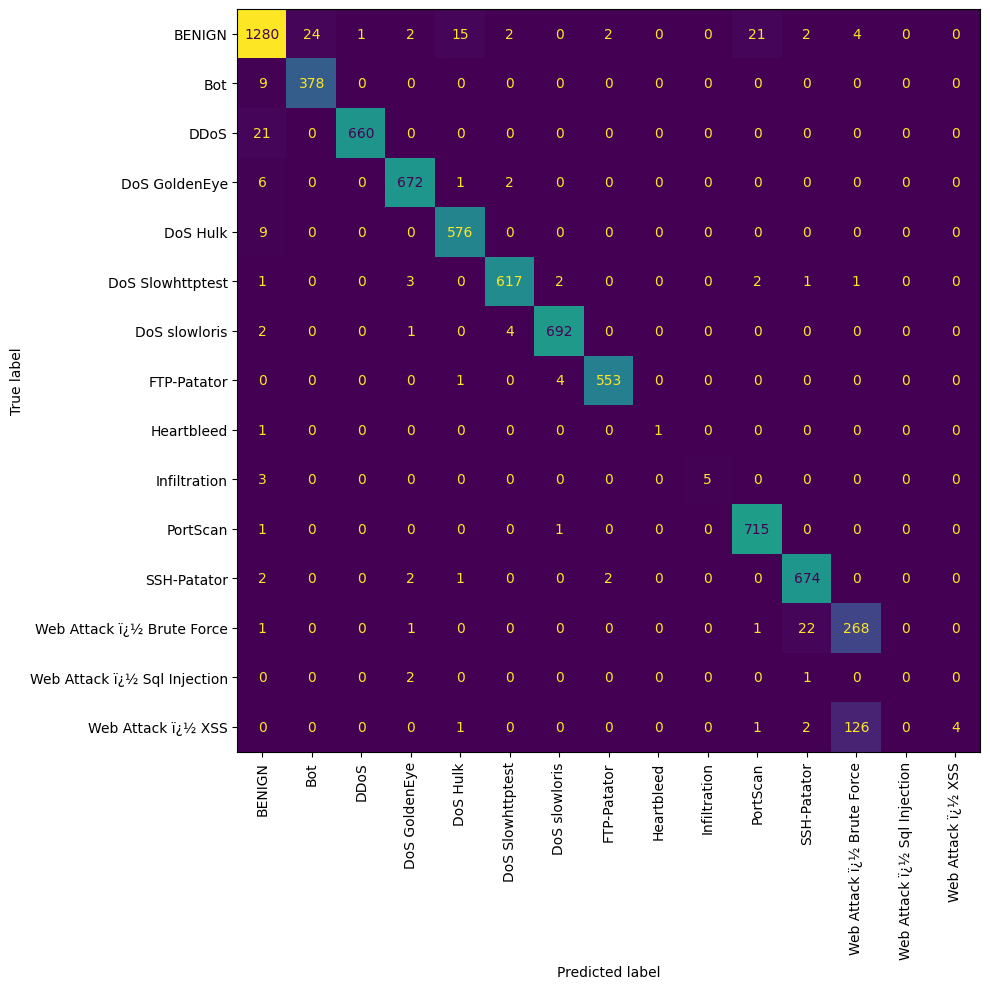

Worst classes (pilot only):


,precision,recall,f1-score,support
Web Attack ï¿½ Sql Injection,0.000000,0.000000,0.000000,3.0
Web Attack ï¿½ XSS,1.000000,0.029851,0.057971,134.0
Heartbleed,1.000000,0.500000,0.666667,2.0
Infiltration,1.000000,0.625000,0.769231,8.0
Web Attack ï¿½ Brute Force,0.671679,0.914676,0.774566,293.0
BENIGN,0.958084,0.946046,0.952027,1353.0
Bot,0.940299,0.976744,0.958175,387.0
SSH-Patator,0.960114,0.989721,0.974693,681.0
DoS Hulk,0.968067,0.984615,0.976271,585.0
PortScan,0.966216,0.997211,0.981469,717.0


In [37]:
test_logits=restore_logits(selected_row,'test')
test_pred=pred_with_bias(test_logits,float(selection['bias']))
metrics=performance(y['test'],test_pred)
final={'model_arch':T4_ARCH,'strategy':selection['strategy'],'trial_id':int(selection['trial_id']),
       'seed':int(selection['seed']),'bias':float(selection['bias']),
       'validation_macro_f1':float(selection['macro_f1']),'test':metrics,
       'split_sha256':sha,'n_features':N_FEATURES,'n_classes':K,'n_test':len(y['test']),
       'protocol':'EXPLORATORY_GROUP_EXACT_DUPLICATES_NOT_HOST_TIME_DISJOINT',
       'warning':'Test reused across past notebooks. Confirm on independent holdout for research claims.'}
(OUTPUT/'final_test_metrics.json').write_text(json.dumps(final,indent=2,ensure_ascii=False))
print(json.dumps(final,indent=2,ensure_ascii=False))
report=classification_report(y['test'],test_pred,labels=all_ids,target_names=classes,output_dict=True,zero_division=0)
pd.DataFrame(report).T.to_csv(OUTPUT/'test_classification_report.csv')
cm=confusion_matrix(y['test'],test_pred,labels=all_ids)
np.save(OUTPUT/'test_confusion_matrix.npy',cm)
test_rows=pd.DataFrame({'true_label':enc.inverse_transform(y['test']),
                        'pred_label':enc.inverse_transform(test_pred),
                        'source_file':df.loc[mask['test'],'_source_file'].to_numpy(),
                        'source_row':df.loc[mask['test'],'_source_row'].to_numpy()})
test_rows.to_csv(OUTPUT/'test_predictions.csv',index=False)
wrong=test_rows[test_rows.true_label.ne(test_rows.pred_label)]
wrong.groupby(['true_label','pred_label']).size().reset_index(name='count').sort_values('count',ascending=False).to_csv(OUTPUT/'test_confusion_pairs.csv',index=False)
shutil.copyfile(str(selected_row['checkpoint']),str(OUTPUT/'selected_best.pt'))
fig,ax=plt.subplots(figsize=(12,10))
ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=90,colorbar=False)
plt.tight_layout();fig.savefig(OUTPUT/'test_confusion_matrix.png',dpi=140);plt.show()
print('Worst classes (pilot only):')
display(pd.DataFrame(report).T.loc[classes].sort_values('f1-score').head(10))

## 11. Lưu manifest và báo cáo so sánh

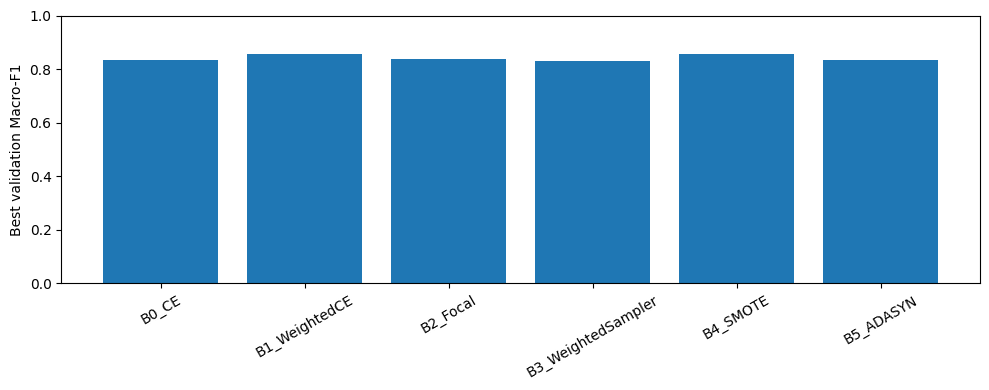

Saved artifacts under: /kaggle/working/nids_outputs/05_CNN_Ablation_V9_Imbalance
Files: 51


In [38]:
manifest_out={'experiment':'05_CNN_Ablation_V9_Imbalance','arch':T4_ARCH,
              'source_03b_path':str(split_path),'split_sha256':sha,
              'feature_variant':feature_variant,'features':features,'classes':classes,
              'search_mode':SEARCH_MODE,'budget':BUDGET,'strategies':STRATEGIES,
              'fixed_hyperparams':{'d_model':64,'heads':4,'dropout':.15,'lr':.001,'weight_decay':.0001,'batch_size':256},
              'xss_target':XSS_SYNTH_TARGET,'smote_k_neighbors':SMOTE_K_NEIGHBORS,
              'focal_gamma':FOCAL_GAMMA,'selected':selection,
              'caveats':['Only XSS is synthesized for SMOTE/ADASYN',
                         'Interpolated network flow values may be physically implausible',
                         'Rare classes do not permit reliable generalization claims',
                         'Test previously inspected; exploratory only',
                         'Duplicate group split is not host/time independent']}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest_out,indent=2,ensure_ascii=False,default=str))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(base_trials['strategy'],base_trials['best_val_macro_f1'])
ax.set_ylim(0,1);ax.set_ylabel('Best validation Macro-F1')
ax.tick_params(axis='x',rotation=30);plt.tight_layout()
fig.savefig(OUTPUT/'imbalance_validation_comparison.png',dpi=150);plt.show()
print('Saved artifacts under:',OUTPUT)
print('Files:',len([p for p in OUTPUT.rglob('*') if p.is_file()]))